# Annotate PPI scores with ClinVar annotations

In [70]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [71]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [72]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [73]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

In [74]:
scores = scores.with_columns(
    (pl.col("normalized_euclid_distance") / scores["normalized_euclid_distance"].max()).alias("normalized_euclid_distance_normalized")
)

In [75]:
scores_pd = scores.to_pandas()
print(scores_pd['clinvar_clnsig_clean'].value_counts())

clinvar_clnsig_clean
1_Pathogenic     239
4_VUS             91
3_Conflicting     75
2_Benign          30
Name: count, dtype: int64


<Axes: title={'center': 'Number of edges per variant'}, ylabel='Frequency'>

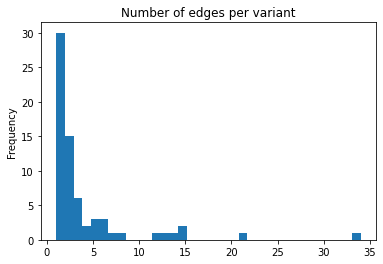

In [111]:
scores_pd.drop_duplicates(subset='symbol').num_edges.plot(kind='hist', bins=35, title='Number of edges per variant')

In [76]:
scores_pd[['euclid_distance', 'normalized_euclid_distance']].describe()

,euclid_distance,normalized_euclid_distance
count,435.000000,435.000000
mean,4660.218598,2588.991614
std,4027.375934,1711.959481
min,6.658363,6.658363
25%,1440.345382,1182.786351
50%,3583.306460,2214.434072
75%,6841.767579,3781.322402
max,19096.786025,9518.154709


In [77]:
scores_pd[scores_pd['clinvar_clnsig_clean'] == '2_Benign'].to_csv(f"{sqy2h_outputs_dir}/auto_variants.csv", index=False)

In [78]:
palette_dict

{'clinvar_clnsig_clean': {'1_Pathogenic': (0.9882352941176471,
   0.5529411764705883,
   0.3843137254901961),
  '2_Benign': (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
  '3_Conflicting': (0.9058823529411765,
   0.5411764705882353,
   0.7647058823529411),
  '4_VUS': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
  '5_Others': (0.4, 0.7607843137254902, 0.6470588235294118),
  '6_No_ClinVar': (0.7019607843137254,
   0.7019607843137254,
   0.7019607843137254)}}

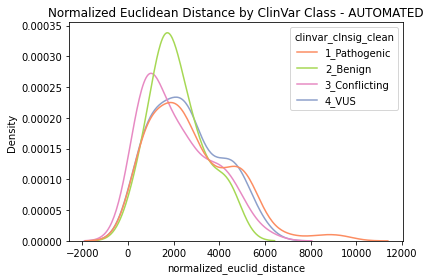

In [79]:
variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=scores,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

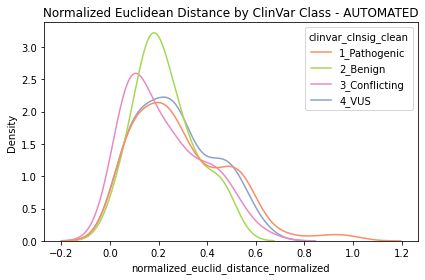

In [98]:
variables = ["normalized_euclid_distance_normalized", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=scores,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

threshold = 0.42

# plt.axvline(x=threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

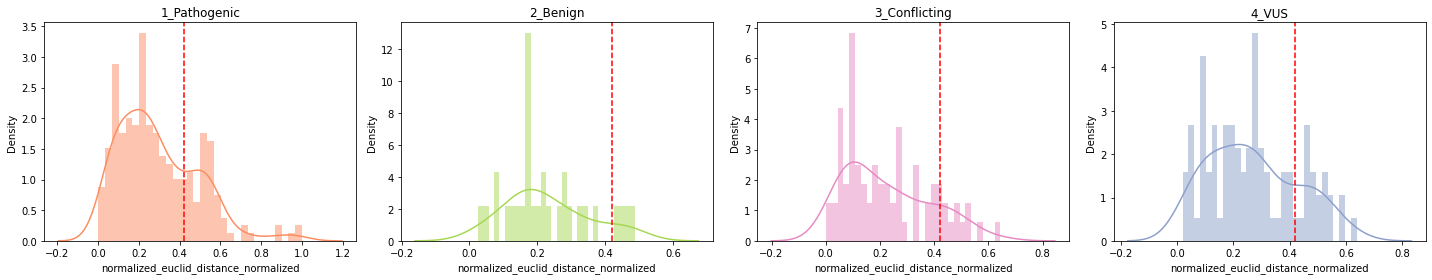

In [93]:
fig, axes = plt.subplots(1, len(hue_order), figsize=(5 * len(hue_order), 4))#, sharey=True)

for ax, class_label in zip(axes, hue_order):
    class_data = scores.filter(pl.col("clinvar_clnsig_clean") == class_label)
    color = palette_dict["clinvar_clnsig_clean"].get(class_label, "gray")
    # Histogram
    ax.hist(class_data[var], bins=30, color=color, alpha=0.5, density=True, label="Histogram")
    # Density curve
    sns.kdeplot(class_data[var], color=color, label="Density", ax=ax)
    ax.set_title(f"{class_label}")
    ax.set_xlabel(var)
    ax.set_ylabel("Density")
    ax.axvline(threshold, color="red", linestyle="--", linewidth=1.5)
    # ax.legend()

plt.tight_layout()
plt.show()

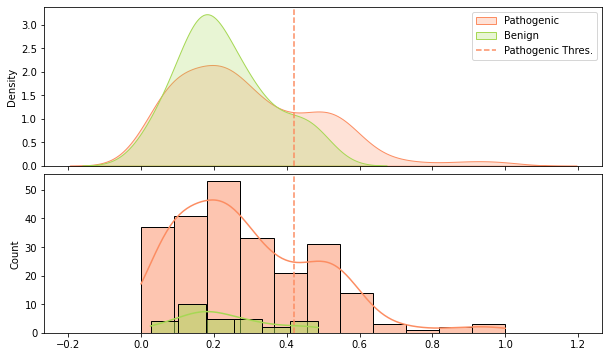

In [97]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

In [94]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")


(30, 37)
(239, 37)
(91, 37)
(75, 37)
With this threshold, we capture 4 benign alleles at ~5% error rate, which is 13.33% of the benign alleles.
With this threshold, we capture 63 pathogenic alleles at ~5% error rate, which is 26.36% of the pathogenic alleles.
With this threshold, we classify 19 VUS and 12 conflicting alleles as pathogenic at ~5% error rate, which is 20.88% and 16.00% of the VUS and conflicting alleles, respectively.


In [83]:
scores_pd['hit'] = scores_pd['normalized_euclid_distance_normalized'] > threshold
scores_pd['hit'] = scores_pd['hit'].astype(int)
scores_pd.hit.sum()
scores_pd.to_csv(f"{sqy2h_outputs_dir}/sqY2H_variant_perturbation_scores_annotated_hit_TEMP.csv", index=False)

In [84]:
# variables = ["normalized_euclid_distance_normalized", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# # Define color mapping for classes
# color_map = {
#     "1_Pathogenic": "red",
#     "2_Benign": "green",
#     "3_Conflicting": "orange",
#     "4_VUS": "blue"
# }

# # Only plot the first variable
# var = variables[-1]
# hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

# sns.kdeplot(
#     data=scores,
#     x=var,
#     hue="clinvar_clnsig_clean",
#     hue_order=hue_order,
#     palette=[color_map.get(k, "gray") for k in hue_order],
#     common_norm=False
# )

# threshold = 0.1

# plt.axvline(x=threshold, color='red', linestyle='--', label='Threshold')

# plt.title('Cosine distance by ClinVar Class - AUTOMATED')
# plt.tight_layout()
# plt.show()
# fig, axes = plt.subplots(1, len(hue_order), figsize=(5 * len(hue_order), 4))#, sharey=True)

# for ax, class_label in zip(axes, hue_order):
#     class_data = scores.filter(pl.col("clinvar_clnsig_clean") == class_label)
#     color = color_map.get(class_label, "gray")
#     # Histogram
#     ax.hist(class_data[var], bins=30, color=color, alpha=0.5, density=True, label="Histogram")
#     # Density curve
#     sns.kdeplot(class_data[var], color=color, label="Density", ax=ax)
#     ax.set_title(f"{class_label}")
#     ax.set_xlabel(var)
#     ax.set_ylabel("Density")
#     ax.axvline(threshold, color="red", linestyle="--", linewidth=1.5)
#     # ax.legend()

# plt.tight_layout()
# plt.show()

In [85]:
# num_edge_filter = 1

# benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

# path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

# vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

# conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

# print(f"With this threshold, we capture {benign_scores.filter(pl.col('cosine_distance') > threshold).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('cosine_distance') > threshold).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
# print(f"With this threshold, we capture {path_scores.filter(pl.col('cosine_distance') > threshold).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('cosine_distance') > threshold).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
# print(f"With this threshold, we classify {vus_scores.filter(pl.col('cosine_distance') > threshold).shape[0]} VUS and {conf_scores.filter(pl.col('cosine_distance') > threshold).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('cosine_distance') > threshold).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('cosine_distance') > threshold).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")


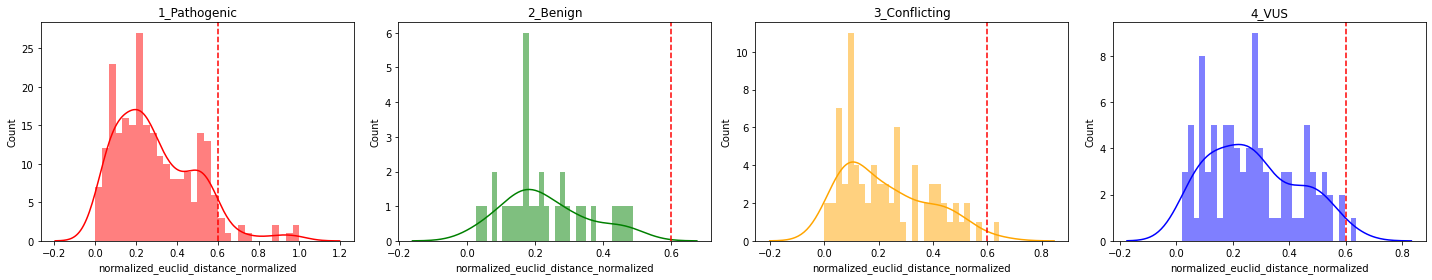

In [86]:
fig, axes = plt.subplots(1, len(hue_order), figsize=(5 * len(hue_order), 4))

for ax, class_label in zip(axes, hue_order):
    class_data = scores.filter(pl.col("clinvar_clnsig_clean") == class_label)
    values = class_data[var]
    color = color_map.get(class_label, "gray")
    
    # Histogram (counts)
    counts, bins, patches = ax.hist(values, bins=30, color=color, alpha=0.5, density=False, label="Histogram")
    
    # KDE scaled to match histogram counts
    kde = sns.kdeplot(values, bw_adjust=1, ax=ax, color=color, label="KDE")
    kde_line = kde.get_lines()[-1]
    x_kde, y_kde = kde_line.get_data()
    
    # Scale KDE y-values to match histogram height
    y_kde_scaled = y_kde * (len(values) * np.diff(bins)[0])
    ax.lines[-1].set_ydata(y_kde_scaled)

    ax.set_title(f"{class_label}")
    ax.set_xlabel(var)
    ax.set_ylabel("Count")
    ax.axvline(0.6, color="red", linestyle="--", linewidth=1.5)
    # ax.legend()  # optional

plt.tight_layout()
plt.show()


In [87]:
# # Define variables to plot
# variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]
# num_vars = len(variables)

# # Create a FacetGrid for multiple subplots
# fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
# hue_order = sorted(scores["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# # Loop through variables and create subplots
# for ax, var in zip(axes, variables):
#     sns.kdeplot(
#         data=scores,
#         x=var,
#         hue="clinvar_clnsig_clean",
#         hue_order=hue_order,
#         ax=ax,
#         palette="Set1",
#         common_norm=False
#     )
#     ax.set_title(var)
# plt.tight_layout()
# plt.show()

(435, 37)
(99, 37)


ValueError: Could not interpret value `frac_per_0.0` for `x`. An entry with this name does not appear in `data`.

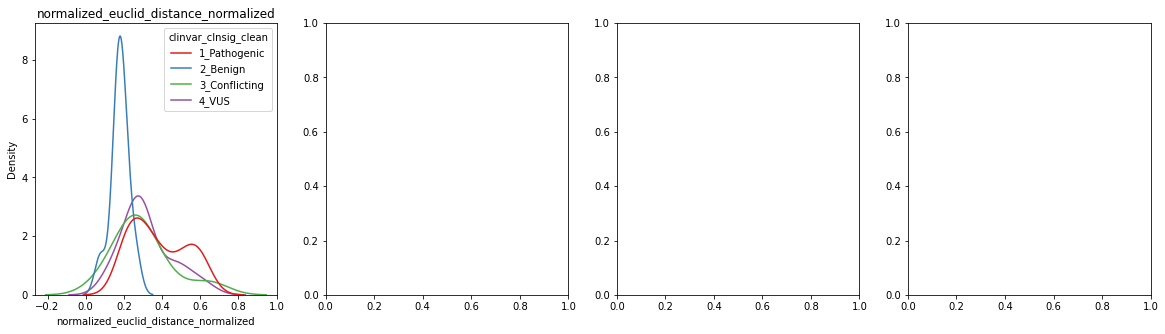

In [88]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(408, 41)
(65, 41)


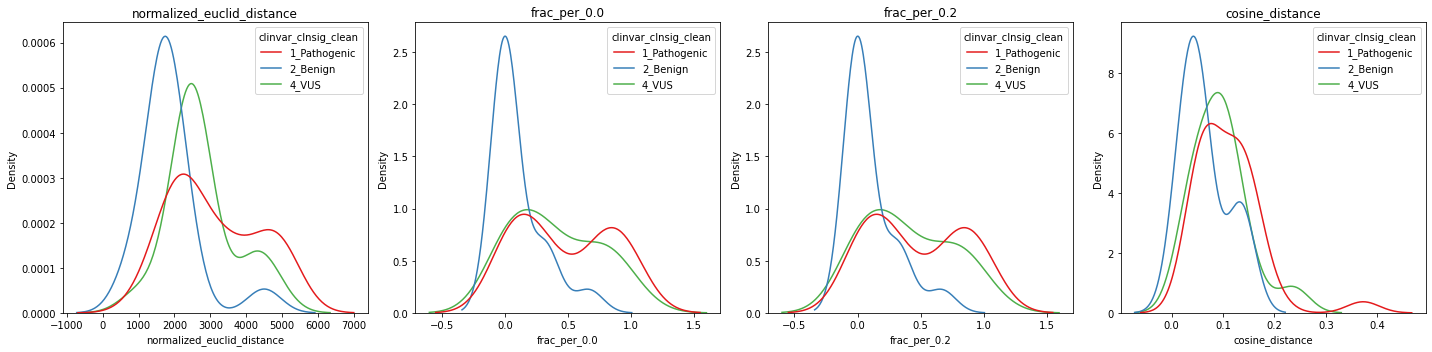

In [ ]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5).filter(pl.col("StarStatus") >= 2)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

## Calculate number of conflicting/VUS that could be reclassified

The normalized scores show good separation. How many alleles would this enable us to putatively reclassify?

(29, 41)
(229, 41)
(78, 41)
(72, 41)


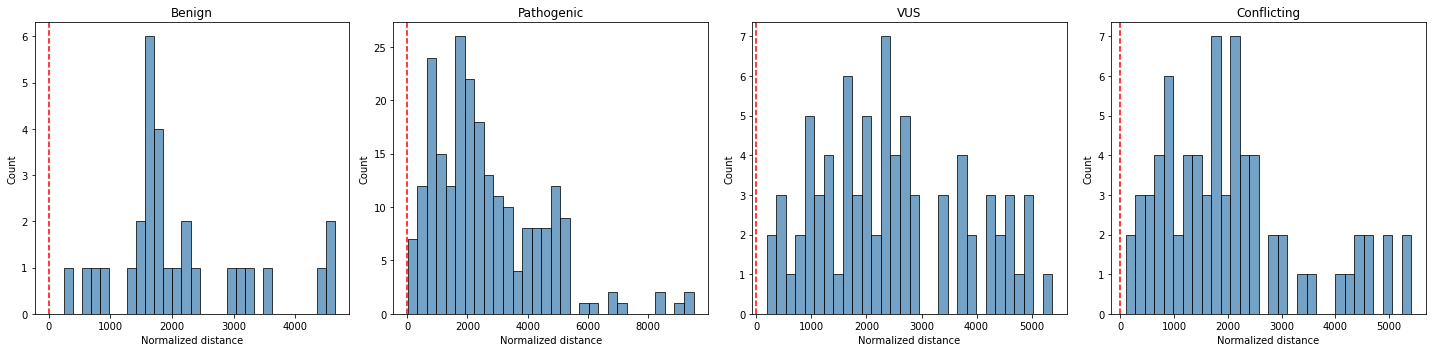

With this threshold, we classify 78 VUS and 72 conflicting alleles as pathogenic at ~5% error rate.


In [ ]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

# Setup subplots
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
plot_data = [
    ("Benign", benign_scores, axs[0]),
    ("Pathogenic", path_scores, axs[1]),
    ("VUS", vus_scores, axs[2]),
    ("Conflicting", conf_scores, axs[3]),
]

# Plot each group
for title, data, ax in plot_data:
    sns.histplot(data=data, x="normalized_euclid_distance", bins=30, color="steelblue", kde=False, ax=ax)
    ax.axvline(0.6, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Normalized distance")
    ax.set_ylabel("Count")
    ax.grid(False)

plt.tight_layout()
plt.show()

print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} conflicting alleles as pathogenic at ~5% error rate.")

# This is ~13.4% of VUS/conflicting

## Consider gnomAD frequency

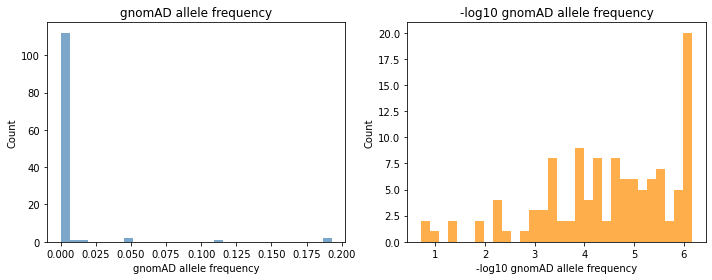

In [ ]:
x = scores['gnomad_af']
x = x.filter(x > 0)

y = -np.log10(x.to_numpy())

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].hist(x, bins=30, color='steelblue', alpha=0.7)
axs[0].set_title("gnomAD allele frequency")
axs[0].set_xlabel("gnomAD allele frequency")
axs[0].set_ylabel("Count")

axs[1].hist(y, bins=30, color='darkorange', alpha=0.7)
axs[1].set_title("-log10 gnomAD allele frequency")
axs[1].set_xlabel("-log10 gnomAD allele frequency")
axs[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

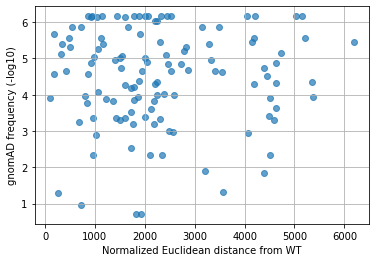

In [ ]:
scores = scores.with_columns(
    (-1*pl.col("gnomad_af").log10()).alias("nlog10_gnomad_af")
)

plt.scatter(scores['normalized_euclid_distance'], scores['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()

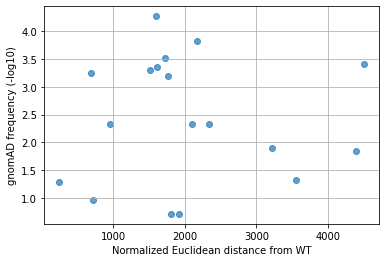

In [ ]:
scores_benign = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")

plt.scatter(scores_benign['normalized_euclid_distance'], scores_benign['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()